[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/linear-transformations/notebook.ipynb)

# Linear Transformations: hands-on

This notebook goes with the [topic README](README.md). You will test the two rules of linearity on candidate maps, push a letter F through rotations, scalings, shears, reflections, and projections, rebuild a matrix from the images of the basis vectors, draw $AB$ against $BA$, see the kernel and range of a singular matrix, differentiate polynomials with a matrix, change basis, shift a shape with homogeneous coordinates, warp a tiny image, write a convolution as a matrix, and watch two linear layers collapse into one. All data are synthetic. It uses NumPy, Matplotlib, SciPy, and SymPy, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so we compare with `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import scipy.linalg as sla
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from numpy.polynomial import polynomial as Poly

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=4, suppress=True)

# the letter F as a closed outline: a 2 x 11 array of (x, y) points
F = np.array([[0, 0], [0.4, 0], [0.4, 0.8], [0.9, 0.8], [0.9, 1.2], [0.4, 1.2],
              [0.4, 1.6], [1.1, 1.6], [1.1, 2], [0, 2], [0, 0]]).T

def show(ax, P, title, color="C0", fill=True):
    if fill:
        ax.fill(P[0], P[1], color=color, alpha=0.3)
    ax.plot(P[0], P[1], color=color, lw=1.5)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title)

def arrow(ax, v, color="k", start=(0, 0), lw=2.5):
    ax.annotate("", xy=np.add(start, v), xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=14))

## 1. Testing the two rules

A map $T$ is linear when $T(\mathbf{u}+\mathbf{v}) = T(\mathbf{u}) + T(\mathbf{v})$ and $T(c\mathbf{v}) = cT(\mathbf{v})$. We cannot prove linearity with random tests, but one failure proves a map is **not** linear. We also print $T(\mathbf{0})$, since a linear map must send the origin to the origin.

In [2]:
rng = np.random.default_rng(0)

def check(T, trials=200):
    add_ok = scale_ok = True
    for _ in range(trials):
        u, v, c = rng.normal(size=2), rng.normal(size=2), rng.normal()
        add_ok &= np.allclose(T(u + v), T(u) + T(v))
        scale_ok &= np.allclose(T(c * v), c * T(v))
    return add_ok, scale_ok

theta = np.deg2rad(30)
candidates = {
    "rotation by 30 degrees": lambda v: np.array([np.cos(theta) * v[0] - np.sin(theta) * v[1],
                                                   np.sin(theta) * v[0] + np.cos(theta) * v[1]]),
    "shear":                  lambda v: np.array([v[0] + v[1], v[1]]),
    "stretch x by 2":         lambda v: np.array([2 * v[0], v[1]]),
    "reflect in the x-axis":  lambda v: np.array([v[0], -v[1]]),
    "project on the x-axis":  lambda v: np.array([v[0], 0.0]),
    "shift by (1, 0.5)":      lambda v: v + np.array([1.0, 0.5]),
    "add a constant 3":       lambda v: v + 3.0,
    "square each entry":      lambda v: v ** 2,
    "absolute value":         lambda v: np.abs(v),
    "(x + y, 2)":             lambda v: np.array([v[0] + v[1], 2.0]),
}
print(f"{'map':24s} {'T(0)':>10s}  additive  scaling  linear?")
for name, T in candidates.items():
    a, s = check(T)
    print(f"{name:24s} {str(T(np.zeros(2)) + 0.0):>10s}  {str(a):8s}  {str(s):7s}  {a and s}")

map                            T(0)  additive  scaling  linear?
rotation by 30 degrees      [0. 0.]  True      True     True
shear                       [0. 0.]  True      True     True
stretch x by 2              [0. 0.]  True      True     True
reflect in the x-axis       [0. 0.]  True      True     True
project on the x-axis       [0. 0.]  True      True     True
shift by (1, 0.5)         [1.  0.5]  False     False    False
add a constant 3            [3. 3.]  False     False    False
square each entry           [0. 0.]  False     False    False
absolute value              [0. 0.]  False     False    False
(x + y, 2)                  [0. 2.]  False     False    False


The shift and the constant fail because they move the origin. Squaring fails the scaling rule even though $T(\mathbf{0}) = \mathbf{0}$. The absolute value keeps scaling for positive $c$ only, so it fails for negative ones, and it also fails additivity: $|1 + (-1)| = 0$ but $|1| + |-1| = 2$.

## 2. A shape through the basic maps

Every matrix is a linear map. Here are five of them applied to the letter F. The determinant is the factor by which areas change: negative means the shape is flipped, and zero means it has been flattened onto a line.

rotation by 30 degrees           det =   1.00
stretch x by 1.5, y by 0.7       det =   1.05
shear                            det =   1.00
reflection in the line y = x     det =  -1.00
projection onto the line y = x   det =   0.00


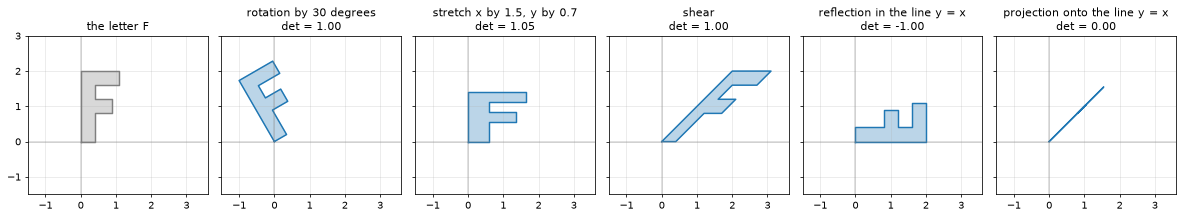

In [3]:
c, s = np.cos(np.deg2rad(30)), np.sin(np.deg2rad(30))
maps = {
    "rotation by 30 degrees": np.array([[c, -s], [s, c]]),
    "stretch x by 1.5, y by 0.7": np.diag([1.5, 0.7]),
    "shear": np.array([[1.0, 1.0], [0.0, 1.0]]),
    "reflection in the line y = x": np.array([[0.0, 1.0], [1.0, 0.0]]),
    "projection onto the line y = x": np.array([[0.5, 0.5], [0.5, 0.5]]),
}
fig, axes = plt.subplots(1, 6, figsize=(17, 3.4), sharex=True, sharey=True)
show(axes[0], F, "the letter F", color="C7")
for ax, (name, A) in zip(axes[1:], maps.items()):
    show(ax, A @ F, f"{name}\ndet = {np.linalg.det(A):.2f}")
    print(f"{name:32s} det = {np.linalg.det(A):6.2f}")
axes[0].set_xlim(-1.5, 3.6); axes[0].set_ylim(-1.5, 3)
plt.tight_layout(); plt.show()

## 3. The matrix from the basis vectors

A linear map is decided by what it does to $\mathbf{e}_1, \dots, \mathbf{e}_n$. Below, `T` is a "black box" function. We feed it the basis vectors, put the answers in columns, and check the resulting matrix against the box on a thousand random inputs.

A =
 [[1.  1. ]
 [0.5 1.5]]
A v = T(v) on 1000 random inputs: True
matches the formula: True


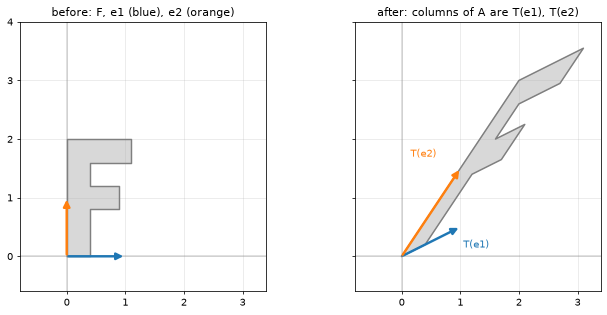

In [4]:
def T(v):                                  # a black box: we only know it is linear
    x, y = v
    return np.array([x + y, 0.5 * x + 1.5 * y])

e1, e2 = np.eye(2)
A = np.column_stack([T(e1), T(e2)])        # images of the basis vectors as columns
print("A =\n", A)

V = np.random.default_rng(1).normal(size=(2, 1000))
print("A v = T(v) on 1000 random inputs:", np.allclose(A @ V, np.array([T(v) for v in V.T]).T))

# the same recipe recovers the rotation matrix from the angle formula
theta = np.deg2rad(40)
rot = lambda v: np.array([np.cos(theta) * v[0] - np.sin(theta) * v[1], np.sin(theta) * v[0] + np.cos(theta) * v[1]])
R = np.column_stack([rot(e1), rot(e2)])
print("matches the formula:", np.allclose(R, [[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
show(axes[0], F, "before: F, e1 (blue), e2 (orange)", color="C7")
arrow(axes[0], e1, "C0"); arrow(axes[0], e2, "C1")
show(axes[1], A @ F, "after: columns of A are T(e1), T(e2)", color="C7")
arrow(axes[1], A[:, 0], "C0"); arrow(axes[1], A[:, 1], "C1")
axes[1].text(1.05, 0.15, "T(e1)", color="C0"); axes[1].text(0.15, 1.7, "T(e2)", color="C1")
axes[0].set_xlim(-0.8, 3.4); axes[0].set_ylim(-0.6, 4)
plt.tight_layout(); plt.show()

## 4. Composition: $AB$ against $BA$

"Do $S$ first, then $R$" has the matrix $RS$: the matrix nearest the vector acts first. Because turning and shearing do not commute, the two orders give different pictures. Two rotations, on the other hand, do commute.

R @ S (shear, then turn) =
 [[ 0. -1.]
 [ 1.  1.]]
S @ R (turn, then shear) =
 [[ 1. -1.]
 [ 1.  0.]]
equal? False


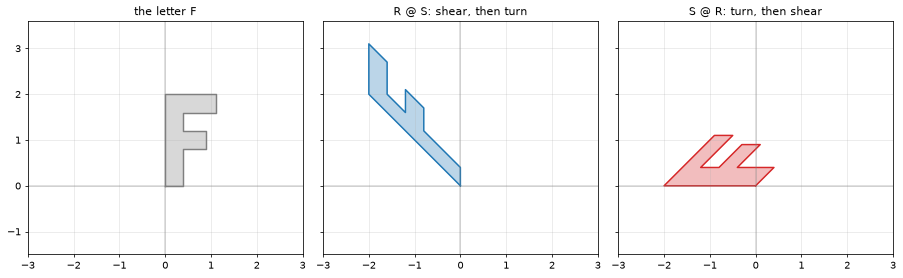

rotations commute, and angles add: True True


In [5]:
R = np.array([[0.0, -1.0], [1.0, 0.0]])    # quarter turn
S = np.array([[1.0, 1.0], [0.0, 1.0]])     # shear
print("R @ S (shear, then turn) =\n", R @ S)
print("S @ R (turn, then shear) =\n", S @ R)
print("equal?", np.allclose(R @ S, S @ R))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
show(axes[0], F, "the letter F", color="C7")
show(axes[1], (R @ S) @ F, "R @ S: shear, then turn", color="C0")
show(axes[2], (S @ R) @ F, "S @ R: turn, then shear", color="C3")
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-1.5, 3.6)
plt.tight_layout(); plt.show()

def rot(a):
    a = np.deg2rad(a); return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
print("rotations commute, and angles add:", np.allclose(rot(20) @ rot(50), rot(50) @ rot(20)), np.allclose(rot(20) @ rot(50), rot(70)))

## 5. Kernel and range of a singular matrix

For $A$ with rows $(1, 2)$ and $(2, 4)$, the kernel is the nullspace and the range is the column space. Every input on a line parallel to the kernel lands on the **same** output, so information is lost. In the left plot each colored line holds inputs with one common output; in the right plot those outputs are the matching colored dots on the range.

kernel direction: [-0.8944  0.4472] | A @ kernel = [0. 0.]
range direction : [-0.4472 -0.8944]
dim kernel + dim range = 1 + 1 = 2
A(1, 0) = [1. 2.] | A(-1, 1) = [1. 2.]  (two inputs, one output)


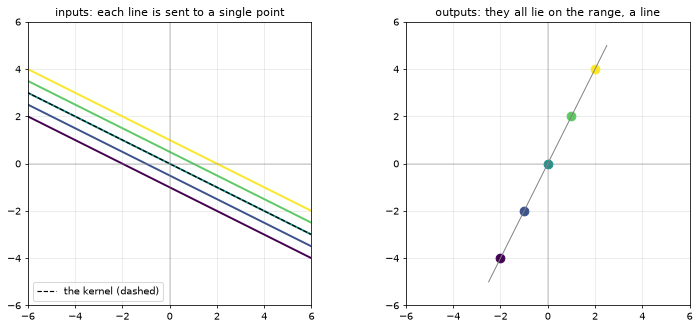

In [6]:
A = np.array([[1.0, 2.0], [2.0, 4.0]])
kernel = sla.null_space(A)                 # basis for the kernel (the nullspace)
rng_basis = sla.orth(A)                    # basis for the range (the column space)
print("kernel direction:", kernel.ravel(), "| A @ kernel =", (A @ kernel).ravel())
print("range direction :", rng_basis.ravel())
print("dim kernel + dim range =", kernel.shape[1], "+", rng_basis.shape[1], "=", A.shape[1])
print("A(1, 0) =", A @ [1, 0], "| A(-1, 1) =", A @ [-1, 1], " (two inputs, one output)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
t = np.linspace(-8, 8, 10)
kd = np.array([2.0, -1.0])                 # a kernel direction
cols = plt.cm.viridis(np.linspace(0, 1, 5))
for col, sc in zip(cols, [-2, -1, 0, 1, 2]):
    base = np.array([sc, 0.0])             # A @ base = sc * (1, 2)
    line = base[:, None] + kd[:, None] * t
    axes[0].plot(*line, color=col, lw=2)
    out = A @ base
    axes[1].plot(*out, "o", color=col, ms=9)
axes[0].set_title("inputs: each line is sent to a single point")
axes[0].plot(*(kd[:, None] * t), "k--", lw=1.2, label="the kernel (dashed)")
axes[0].legend(loc="lower left")
axes[1].plot(*(np.array([1.0, 2.0])[:, None] * np.linspace(-2.5, 2.5, 5)), color="gray", lw=1)
axes[1].set_title("outputs: they all lie on the range, a line")
for ax in axes:
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
plt.tight_layout(); plt.show()

## 6. The derivative as a matrix

On $\mathcal{P}_3$ (polynomials of degree at most 3) with the basis $1, x, x^2, x^3$, the derivative sends $1 \mapsto 0$, $x \mapsto 1$, $x^2 \mapsto 2x$, $x^3 \mapsto 3x^2$. Those images, in coordinates, are the columns of $D$. We check it against `numpy.polynomial` on random polynomials and against SymPy's exact derivative.

D @ p        = [ 5. -2. 12.  0.]
polyder(p)   = [ 5. -2. 12.]
sympy        = 12*x**2 - 2*x + 5 | coefficients: [5, -2, 12, 0]
matches polyder on 50 random cubics: True
rank of D = 3 | kernel basis: [-1.  0.  0.  0.]
D^4 is the zero matrix: True


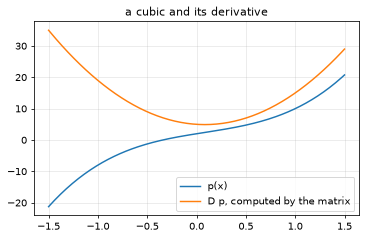

In [7]:
D = np.array([[0, 1, 0, 0],
              [0, 0, 2, 0],
              [0, 0, 0, 3],
              [0, 0, 0, 0]], dtype=float)

p = np.array([2.0, 5.0, -1.0, 4.0])        # 2 + 5x - x^2 + 4x^3, lowest power first
print("D @ p        =", D @ p)
print("polyder(p)   =", Poly.polyder(p))

x = sp.symbols("x")
expr = 2 + 5 * x - x**2 + 4 * x**3
dexpr = sp.diff(expr, x)
print("sympy        =", dexpr, "| coefficients:", [dexpr.coeff(x, k) for k in range(4)])

rng = np.random.default_rng(2)
ok = all(np.allclose(D @ q, np.append(Poly.polyder(q), 0.0)) for q in rng.normal(size=(50, 4)))
print("matches polyder on 50 random cubics:", ok)

print("rank of D =", np.linalg.matrix_rank(D), "| kernel basis:", sla.null_space(D).ravel().round(3))
print("D^4 is the zero matrix:", np.allclose(np.linalg.matrix_power(D, 4), 0))

# a picture: a cubic and the derivative computed by the matrix
xs = np.linspace(-1.5, 1.5, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(xs, Poly.polyval(xs, p), label="p(x)")
ax.plot(xs, Poly.polyval(xs, D @ p), label="D p, computed by the matrix")
ax.legend(); ax.grid(alpha=0.3); ax.set_title("a cubic and its derivative"); plt.show()

## 7. Change of basis

The same transformation has a different matrix in each basis. If the columns of $M$ are the new basis vectors, the matrix in the new basis is $B = M^{-1}AM$. Here $A$ has rows $(3, 1)$ and $(0, 2)$ and the new basis is $(1, 0)$, $(1, -1)$.

B = M^-1 A M =
 [[3. 0.]
 [0. 2.]]
new coordinates of v: [ 7. -5.] | B c converts back to A v: True
det A, det B       : 6.0 6.0
trace A, trace B   : 5.0 5.0
eigenvalues A, B   : [2. 3.] [2. 3.]


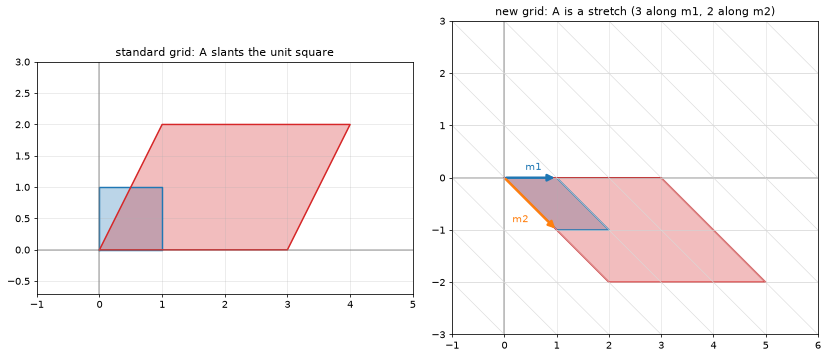

In [8]:
A = np.array([[3.0, 1.0], [0.0, 2.0]])
M = np.array([[1.0, 1.0], [0.0, -1.0]])
B = np.linalg.inv(M) @ A @ M
print("B = M^-1 A M =\n", B)

v = np.array([2.0, 5.0])
c = np.linalg.solve(M, v)                       # coordinates of v in the new basis
print("new coordinates of v:", c, "| B c converts back to A v:", np.allclose(M @ (B @ c), A @ v))
print("det A, det B       :", np.linalg.det(A), np.linalg.det(B))
print("trace A, trace B   :", np.trace(A), np.trace(B))
print("eigenvalues A, B   :", np.sort(np.linalg.eigvals(A)), np.sort(np.linalg.eigvals(B)))

sq = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]], float)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
show(axes[0], sq, "standard grid: A slants the unit square", color="C0")
show(axes[0], A @ sq, "standard grid: A slants the unit square", color="C3")
show(axes[1], M @ sq, "new grid: A is a stretch (3 along m1, 2 along m2)", color="C0")
show(axes[1], M @ (B @ sq), "new grid: A is a stretch (3 along m1, 2 along m2)", color="C3")
tt = np.linspace(-12, 12, 40)
for k in range(-12, 13):
    for a_, b_ in [(tt, np.full_like(tt, k)), (np.full_like(tt, k), tt)]:
        Q = M @ np.array([a_, b_]); axes[1].plot(*Q, color="0.85", lw=0.6)
arrow(axes[1], M[:, 0], "C0"); arrow(axes[1], M[:, 1], "C1")
axes[1].text(0.4, 0.15, "m1", color="C0"); axes[1].text(0.15, -0.85, "m2", color="C1")
axes[0].set_xlim(-1, 5); axes[0].set_ylim(-0.7, 3)
axes[1].set_xlim(-1, 6); axes[1].set_ylim(-3, 3)
plt.tight_layout(); plt.show()

## 8. A diagonalizing basis

If we choose the eigenvectors of $A$ as the basis, the matrix becomes diagonal, which is the meaning of $A = S\Lambda S^{-1}$. `np.linalg.eig` finds such a basis for us (how it works is the next topic). A unit circle is sent to an ellipse whose axes are those special directions.

eigenvalues: [3. 1.]
S^-1 A S =
 [[3. 0.]
 [0. 1.]]
A = S Lambda S^-1: True
A^10 = S Lambda^10 S^-1: True


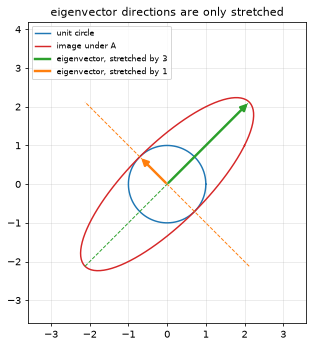

In [9]:
A = np.array([[2.0, 1.0], [1.0, 2.0]])
vals, S = np.linalg.eig(A)                       # columns of S are eigenvectors
Lam = np.round(np.linalg.inv(S) @ A @ S, 12) + 0.0
print("eigenvalues:", vals)
print("S^-1 A S =\n", Lam)
print("A = S Lambda S^-1:", np.allclose(A, S @ np.diag(vals) @ np.linalg.inv(S)))

# powers are easy in the eigenbasis
print("A^10 = S Lambda^10 S^-1:", np.allclose(np.linalg.matrix_power(A, 10), S @ np.diag(vals**10) @ np.linalg.inv(S)))

ang = np.linspace(0, 2 * np.pi, 200)
circle = np.array([np.cos(ang), np.sin(ang)])
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.plot(*circle, color="C0", label="unit circle")
ax.plot(*(A @ circle), color="C3", label="image under A")
for k, colr in zip(range(2), ["C2", "C1"]):
    d = S[:, k]
    ax.plot(*np.array([-3 * d, 3 * d]).T, "--", color=colr, lw=1)
    arrow(ax, d * vals[k], colr)
    ax.plot([], [], color=colr, lw=2.5, label=f"eigenvector, stretched by {vals[k]:.0f}")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 4.2); ax.set_title("eigenvector directions are only stretched")
plt.show()

## 9. Translation with an extra coordinate

A shift is not linear, but in homogeneous coordinates $(x, y, 1)$ it is a $3 \times 3$ matrix. A chain of turns and shifts is then a product, and the order matters.

turn_then_shift =
 [[ 0. -1.  2.]
 [ 1.  0.  1.]
 [ 0.  0.  1.]]
applied to (3, 4): [-2.  4.  1.]
directly         : [-2  4]
same as the other order? False


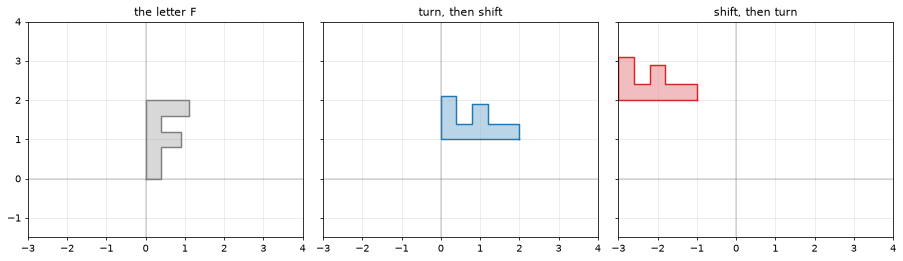

In [10]:
def hom(A=np.eye(2), b=(0.0, 0.0)):
    H = np.eye(3); H[:2, :2] = A; H[:2, 2] = b; return H

turn = hom(np.array([[0.0, -1.0], [1.0, 0.0]]))      # quarter turn
shift = hom(b=(2.0, 1.0))                            # shift by (2, 1)
F3 = np.vstack([F, np.ones(F.shape[1])])             # F with a row of ones appended

turn_then_shift = shift @ turn
shift_then_turn = turn @ shift
print("turn_then_shift =\n", turn_then_shift)
print("applied to (3, 4):", (turn_then_shift @ [3.0, 4.0, 1.0]))
print("directly         :", np.array([[0, -1], [1, 0]]) @ [3, 4] + [2, 1])
print("same as the other order?", np.allclose(turn_then_shift, shift_then_turn))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
show(axes[0], F, "the letter F", color="C7")
show(axes[1], (turn_then_shift @ F3)[:2], "turn, then shift", color="C0")
show(axes[2], (shift_then_turn @ F3)[:2], "shift, then turn", color="C3")
axes[0].set_xlim(-3, 4); axes[0].set_ylim(-1.5, 4)
plt.tight_layout(); plt.show()

## 10. An image warped by a linear map

Rotating, scaling, and shearing an image are linear maps on the pixel coordinates. We use a tiny synthetic image: a bright F on a dark background with a gradient. `scipy.ndimage.affine_transform` wants the map from **output** pixel to **input** pixel, so we pass the **inverse** of the matrix we want, and keep the image centered by shifting the center to the origin and back. Coordinates are (row, column) with rows counting downward, so a positive angle turns the picture clockwise on screen.

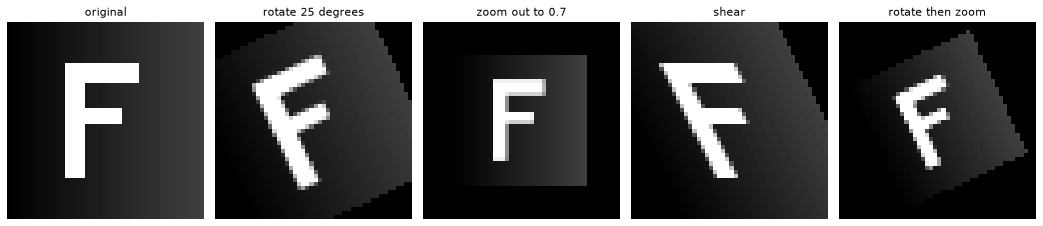

warp is linear in the image: True
mean pixel difference, two warps vs one combined warp: 0.013


In [11]:
img = np.zeros((48, 48))
img += np.linspace(0, 0.25, 48)[None, :]                      # a faint gradient
img[10:38, 14:19] = 1.0                                        # stem of the F
img[10:15, 14:32] = 1.0                                        # top bar
img[21:25, 14:28] = 1.0                                        # middle bar

def warp(image, A):
    # new image[p] = old image[A^-1 p], with coordinates (row, col) and the center kept fixed
    center = (np.array(image.shape) - 1) / 2
    Ainv = np.linalg.inv(A)
    return ndi.affine_transform(image, Ainv, offset=center - Ainv @ center, order=1, mode="constant")

a = np.deg2rad(25)
rotate = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
zoom = np.diag([0.7, 0.7])
shear = np.array([[1.0, 0.0], [0.5, 1.0]])
pics = [("original", img), ("rotate 25 degrees", warp(img, rotate)),
        ("zoom out to 0.7", warp(img, zoom)), ("shear", warp(img, shear)),
        ("rotate then zoom", warp(img, zoom @ rotate))]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
for ax, (name, im) in zip(axes, pics):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
# warping is itself linear in the image: warp(a*img1 + b*img2) = a*warp(img1) + b*warp(img2)
other = np.random.default_rng(4).random(img.shape)
print("warp is linear in the image:", np.allclose(warp(2 * img - 3 * other, rotate), 2 * warp(img, rotate) - 3 * warp(other, rotate)))
# one combined matrix versus two warps in a row: close, not identical (each warp interpolates and crops)
diff = np.abs(warp(warp(img, rotate), zoom) - warp(img, zoom @ rotate)).mean()
print(f"mean pixel difference, two warps vs one combined warp: {diff:.3f}")

## 11. Convolution as a matrix

A 1D convolution is a linear map, so it has a matrix: a banded **Toeplitz** matrix (constant along each diagonal) whose rows are shifted copies of the flipped kernel. Both the "valid" and the "full" versions are checked against `np.convolve`.

valid convolution matrix (3 x 5):
 [[3. 2. 1. 0. 0.]
 [0. 3. 2. 1. 0.]
 [0. 0. 3. 2. 1.]]
True
full convolution matrix shape: (7, 5) True
distinct nonzero values in a (14, 12) matrix: [1. 2. 3.]


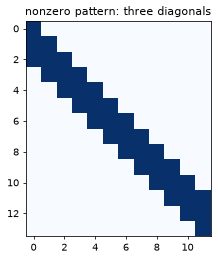

In [12]:
w = np.array([1.0, 2.0, 3.0])
x = np.array([1.0, 0.0, 2.0, -1.0, 4.0])
n, k = len(x), len(w)

C_valid = np.zeros((n - k + 1, n))
for i in range(n - k + 1):
    C_valid[i, i:i + k] = w[::-1]
print("valid convolution matrix (3 x 5):\n", C_valid)
print(np.allclose(C_valid @ x, np.convolve(x, w, mode="valid")))

C_full = sla.toeplitz(np.r_[w, np.zeros(n - 1)], np.r_[w[0], np.zeros(n - 1)])   # (n + k - 1) x n
print("full convolution matrix shape:", C_full.shape, np.allclose(C_full @ x, np.convolve(x, w, mode="full")))

# a bigger signal: the matrix has only 3 distinct numbers, repeated
x_long = np.random.default_rng(3).normal(size=12)
C_long = sla.toeplitz(np.r_[w, np.zeros(11)], np.r_[w[0], np.zeros(11)])
print("distinct nonzero values in a", C_long.shape, "matrix:", np.unique(C_long[C_long != 0]))
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(C_long != 0, cmap="Blues"); ax.set_title("nonzero pattern: three diagonals")
plt.show()

## 12. Two linear layers collapse

A layer $\mathbf{x} \mapsto W_1\mathbf{x}$ followed by $\mathbf{h} \mapsto W_2\mathbf{h}$ is the single map $W_2W_1$. A ReLU in between prevents that. A narrow middle layer also limits the rank of the combined map.

In [13]:
rng = np.random.default_rng(1)
W1 = rng.normal(size=(256, 784))
W2 = rng.normal(size=(10, 256))
x = rng.normal(size=784)
W = W2 @ W1

relu = lambda z: np.maximum(z, 0)
print("single matrix shape      :", W.shape)
print("two layers = one matrix  :", np.allclose(W2 @ (W1 @ x), W @ x))
print("parameters: two layers vs one:", W1.size + W2.size, "vs", W.size)
print("with a ReLU in between   :", np.allclose(W2 @ relu(W1 @ x), W @ x))

# a bottleneck: 784 -> 2 -> 784 can never produce more than rank 2
U = rng.normal(size=(784, 2)); V = rng.normal(size=(2, 784))
print("rank of a 784 x 784 map through a 2-wide middle layer:", np.linalg.matrix_rank(U @ V))

single matrix shape      : (10, 784)
two layers = one matrix  : True
parameters: two layers vs one: 203264 vs 7840
with a ReLU in between   : False
rank of a 784 x 784 map through a 2-wide middle layer: 2


## Recap and next steps

* A map is **linear** when $T(\mathbf{u}+\mathbf{v}) = T(\mathbf{u})+T(\mathbf{v})$ and $T(c\mathbf{v}) = cT(\mathbf{v})$. It sends $\mathbf{0}$ to $\mathbf{0}$ and keeps lines straight. Shifts and squaring fail.
* The matrix of a linear map has the images of the basis vectors as columns, and a product of matrices is a composition of maps, with the first map nearest the vector.
* The **kernel** is the nullspace and the **range** is the column space. A singular matrix collapses whole lines to single points.
* In a new basis $M$ the same map has the matrix $B = M^{-1}AM$. Similar matrices share determinant, trace, and eigenvalues, and a basis of eigenvectors makes the matrix diagonal.
* An extra coordinate turns shifts into matrices. Convolutions and dense layers are linear maps, and stacked linear layers collapse into one.

Next: the [Singular Value Decomposition](../singular-value-decomposition/README.md), which finds the best pair of bases for any matrix.